# 28. Kronecker Products and Linear Matrix Equations
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The size of the Sylvester solution as eigenvalues approach. Left: for normal $A$ and $B$ (Hermitian, $5\times5$) with spectral separation $\delta$, the ratio $\lVert X\rVert_F\,\delta/\lVert C\rVert_F$ (blue, $200$ random $C$ per $\delta$) never exceeds $1$, as the theorem guarantees. Right: for non-normal $A$ and $B$ with the same eigenvalues (random similarity transforms with condition number about $50$), the ratio is often far larger: eigenvalue separation no longer controls the solution.

Text(0, 0.5, '$\\|X\\|_F\\,\\delta/\\|C\\|_F$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


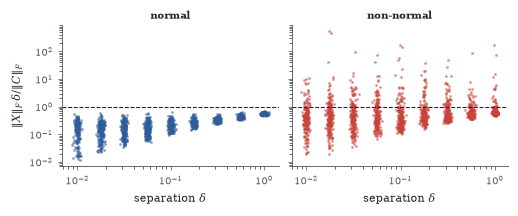

In [2]:
from scipy.linalg import solve_sylvester
rng = np.random.default_rng(0); deltas = np.logspace(-2, 0, 9); m = 5
def ratios(delta, nonnormal):
    la = np.linspace(0, 1, m) + 1 + delta; lb = np.linspace(-1, 0, m) + 1; out = []
    for _ in range(200):
        if nonnormal:
            Sa = rng.normal(size=(m, m)) + 3 * np.eye(m); Sb = rng.normal(size=(m, m)) + 3 * np.eye(m)
            Am, Bm = Sa @ np.diag(la) @ np.linalg.inv(Sa), Sb @ np.diag(lb) @ np.linalg.inv(Sb)
        else:
            Qa, _ = np.linalg.qr(rng.normal(size=(m, m))); Qb, _ = np.linalg.qr(rng.normal(size=(m, m))); Am, Bm = Qa @ np.diag(la) @ Qa.T, Qb @ np.diag(lb) @ Qb.T
        Cm = rng.normal(size=(m, m)); Xm = solve_sylvester(Am, -Bm, Cm); out.append(np.linalg.norm(Xm) * delta / np.linalg.norm(Cm))
    return np.array(out)
fig, axs = plt.subplots(1, 2, figsize=(W, 1.85), sharey=True)
for ax, nn, ttl in [(axs[0], False, "normal"), (axs[1], True, "non-normal")]:
    for d in deltas:
        r = ratios(d, nn); ax.scatter(np.full(len(r), d) * np.exp(rng.normal(0, 0.04, len(r))), r, s=1, color=BLUE if not nn else RED, alpha=0.4)
    ax.axhline(1, color=INK, lw=0.7, ls="--"); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"separation $\delta$"); ax.set_title(ttl, fontsize=6.5)
axs[0].set_ylabel(r"$\|X\|_F\,\delta/\|C\|_F$")

In [3]:
import time
from scipy.linalg import schur, solve_triangular
def bartels_stewart(A, B, C):
    T, U = schur(A, output="complex"); S, V = schur(B, output="complex"); D = U.conj().T @ C @ V; m, n = C.shape; Y = np.zeros((m, n), complex)
    for k in range(n):
        rhs = D[:, k] + Y[:, :k] @ S[:k, k]; Y[:, k] = solve_triangular(T - S[k, k] * np.eye(m), rhs)
    return U @ Y @ V.conj().T
rng = np.random.default_rng(1)
for n in (10, 20, 40):
    A = rng.normal(size=(n, n)) + n * np.eye(n); B = rng.normal(size=(n, n)); C = rng.normal(size=(n, n))
    t0 = time.perf_counter(); X1 = bartels_stewart(A, B, C).real; t1 = time.perf_counter()
    X2 = np.linalg.solve(np.kron(np.eye(n), A) - np.kron(B.T, np.eye(n)), C.reshape(-1, order="F")).reshape(n, n, order="F"); t2 = time.perf_counter()
    print(f"n={n:3d}: residual {np.linalg.norm(A @ X1 - X1 @ B - C):.1e}, agree {np.allclose(X1, X2)}, Bartels-Stewart {1e3*(t1-t0):6.1f} ms, Kronecker {1e3*(t2-t1):7.1f} ms")

n= 10: residual 1.9e-14, agree True, Bartels-Stewart    1.9 ms, Kronecker     0.3 ms
n= 20: residual 6.5e-14, agree True, Bartels-Stewart    1.1 ms, Kronecker     5.2 ms
n= 40: residual 1.4e-13, agree True, Bartels-Stewart    3.7 ms, Kronecker   105.2 ms


The commutant of a Jordan matrix $J=J_3(0)\oplus J_2(0)\oplus J_2(1)$, computed as the null space of $I\otimes J-J^{\mathsf T}\otimes I$. Left: the sparsity pattern of a generic commuting matrix, with upper triangular Toeplitz blocks linking the Jordan blocks of the same eigenvalue and zeros elsewhere. Right: the formula $\sum\min(n_i,n_j)$ gives $3+2+2+2+2=11$, the dimension found numerically.

Text(0.08, 0.18, '$+\\min(2,2)+\\min(2,2)=11$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


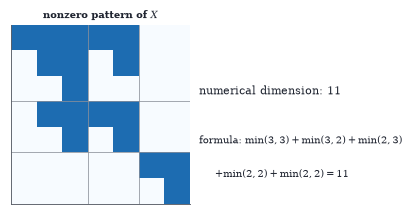

In [4]:
from scipy.linalg import null_space, block_diag
Jb = lambda k, lam: lam * np.eye(k) + np.eye(k, k=1); Jm = block_diag(Jb(3, 0.0), Jb(2, 0.0), Jb(2, 1.0)); n = 7
Ns = null_space(np.kron(np.eye(n), Jm) - np.kron(Jm.T, np.eye(n))); Xg = (Ns @ np.random.default_rng(2).normal(size=Ns.shape[1])).reshape(n, n, order="F")
fig, axs = plt.subplots(1, 2, figsize=(W * 0.8, 1.9), gridspec_kw={"width_ratios": [1, 1.1]})
axs[0].imshow(np.abs(Xg) > 1e-10, cmap="Blues", vmin=0, vmax=1.3)
for b in (2.5, 4.5): axs[0].axhline(b, color=GRAY, lw=0.5); axs[0].axvline(b, color=GRAY, lw=0.5)
axs[0].set_xticks([]); axs[0].set_yticks([]); axs[0].set_title("nonzero pattern of $X$", fontsize=6.5)
axs[1].axis("off"); axs[1].text(0, 0.6, f"numerical dimension: {Ns.shape[1]}", fontsize=7.5); axs[1].text(0, 0.35, r"formula: $\min(3,3)+\min(3,2)+\min(2,3)$", fontsize=6.5); axs[1].text(0.08, 0.18, r"$+\min(2,2)+\min(2,2)=11$", fontsize=6.5)

Approximating a $64\times64$ image made of two repeated $8\times8$ tiles (a disc and stripes) under slowly varying envelopes, plus a large disc, by sums of Kronecker products $\sum_{k\le r}\sigma_kU_k\otimes V_k$ with $8\times8$ factors (top row) and by rank-$r$ truncated SVDs (bottom row). Both kinds of term cost $128$ numbers. Two Kronecker terms reproduce both textures almost exactly, while the truncated SVD needs several times as many terms; the faint large disc, which does not repeat from block to block, is the part the Kronecker terms find hardest. Which structure is more economical depends on the data.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


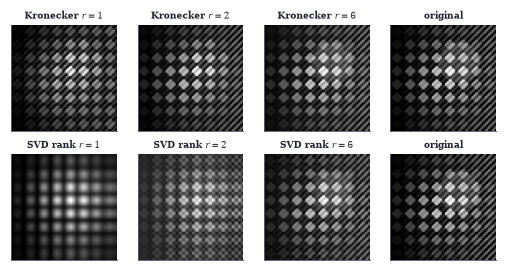

In [5]:
t8 = np.linspace(-1, 1, 8); T1, T2 = np.meshgrid(t8, t8)
B1 = np.exp(-(T1**2 + T2**2) * 1.5); C1 = (np.sqrt(T1**2 + T2**2) < 0.75).astype(float)     # bump envelope, disc tile
B2 = (T1 + 1) / 2; C2 = (np.mod(np.arange(8)[:, None] + np.arange(8)[None, :], 4) < 2).astype(float)  # ramp, stripe tile
gx = np.linspace(-1, 1, 64); GX, GY = np.meshgrid(gx, gx)
img = np.kron(B1, C1) + 0.6 * np.kron(B2, C2) + 0.25 * ((GX - 0.3) ** 2 + (GY + 0.3) ** 2 < 0.15)
def rearrange(A, m, p):
    return np.array([A[i * p:(i + 1) * p, j * p:(j + 1) * p].reshape(-1, order="F") for j in range(m) for i in range(m)])
Rm = rearrange(img, 8, 8); Ur, sr, Vrt = np.linalg.svd(Rm); Ui, si, Vit = np.linalg.svd(img)
def kron_approx(r):
    out = np.zeros_like(img)
    for k in range(r): out += sr[k] * np.kron(Ur[:, k].reshape(8, 8, order="F"), Vrt[k].reshape(8, 8, order="F"))
    return out
fig, axs = plt.subplots(2, 4, figsize=(W, 2.35))
for c, r in enumerate([1, 2, 6, 64]):
    axs[0, c].imshow(kron_approx(r) if r < 64 else img, cmap="gray"); axs[0, c].set_title(f"Kronecker $r={r}$" if r < 64 else "original", fontsize=6)
    axs[1, c].imshow((Ui[:, :r] * si[:r]) @ Vit[:r] if r < 64 else img, cmap="gray"); axs[1, c].set_title(f"SVD rank $r={r}$" if r < 64 else "original", fontsize=6)
for ax in axs.ravel(): ax.set_xticks([]); ax.set_yticks([])

In [6]:
from scipy.integrate import quad_vec
from scipy.linalg import expm
A2 = np.array([[2.0, 5], [0, 3]]); B2 = np.array([[-1.0, 0], [4, -2]]); C2 = np.random.default_rng(0).normal(size=(2, 2))
Xq, err = quad_vec(lambda t: expm(-t * A2) @ C2 @ expm(t * B2), 0, np.inf)
print("quadrature:\n", np.round(Xq, 8)); print("solve_sylvester:\n", np.round(solve_sylvester(A2, -B2, C2), 8))

quadrature:
 [[-0.33890106 -0.05925125]
 [ 0.18108569  0.02098002]]
solve_sylvester:
 [[-0.33890106 -0.05925125]
 [ 0.18108569  0.02098002]]


In [7]:
rng = np.random.default_rng(5); A4 = rng.normal(size=(4, 4)); lam = np.linalg.eigvals(A4)
Lop = np.kron(np.eye(4), A4.T) + np.kron(A4.T, np.eye(4))
print(np.allclose(np.sort_complex(np.linalg.eigvals(Lop)), np.sort_complex((lam[:, None] + lam[None, :]).ravel())))

False


In [8]:
rng = np.random.default_rng(6); A4, B4 = rng.normal(size=(4, 4)), rng.normal(size=(4, 4))
S = np.zeros((16, 4))
for i in range(4): S[i * 4 + i, i] = 1
print("A o B = S^T (A kron B) S:", np.allclose(A4 * B4, S.T @ np.kron(A4, B4) @ S))
print("||A o B|| =", round(np.linalg.norm(A4 * B4, 2), 4), " <= ||A|| ||B|| =", round(np.linalg.norm(A4, 2) * np.linalg.norm(B4, 2), 4))

A o B = S^T (A kron B) S: True
||A o B|| = 3.9468  <= ||A|| ||B|| = 13.1873
